In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
file_path = r"C:\Users\Keshav Kalani\Desktop\lets do this\practicals\ML Codes\ML dataset\emails.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully")
print("Rows and columns:", df.shape)
print(df.head())

Dataset loaded successfully
Rows and columns: (5172, 3002)
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Column names:
['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in', 'on', 'is', 'this', 'enron', 'i', 'be', 'that', 'will', 'have', 'with', 'your', 'at', 'we', 's', 'are', 'it', 'by', 'com', 'as', 'from', 'gas', 'or', 'not', 'me', 'deal', 'if', 'meter', 'hpl', 'please', 're', 'e', 'any', 'our', 'corp', 'can', 'd', 'all', 'has', 'was', 'know', 'need', 'an', 'forwarded', 'new', 't', 'may', 'up', 'j', 'mmbtu', 'should', 'do', 'am', 'get', 'out', 'see', 'no', 'there', 'price', 'daren', 'but', 'been', 'company', 'l', 'these', 'let', 'so', 'would', 'm', 'into', 'xls', 'farmer', 'attached', 'us', 'information', 'they', 'message', 'day', 'time', 'my', 'one', 'what', 'only', 'http', 'th', 'volume', 'mail', 'contract', 'which', 'month', 'more', 'robert', 'sitara', 'about', 'texas', 'nom', 'energy', 'pec', 'questions', 'www', 'deals', 'volumes', 'pm', 'ena', 'now', 'their', 'file', 'some', 'email', 'just', 'also', 'call', 'change', 'other', 'here', 'like', 'b', 'flow', 'n

In [4]:
target_column = "Prediction"

if target_column not in df.columns:
    raise ValueError(
        "Prediction column not found. Check the column names printed in Step 3."
    )

# Remove rows with missing values
df = df.dropna().copy()

# Separate the target label from the input features
y = df[target_column]

# Remove target and email ID columns from the features
columns_to_drop = [target_column]
columns_to_drop += [
    col for col in df.columns
    if col.lower() in ["email no.", "email_no", "email", "unnamed: 0"]
]

X = df.drop(columns=columns_to_drop)

print("Feature data shape:", X.shape)
print("Target data shape:", y.shape)
print("\nClass counts:")
print(y.value_counts())

Feature data shape: (5172, 2999)
Target data shape: (5172,)

Class counts:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 4137
Testing rows: 1035


In [6]:
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn_model.fit(X_train, y_train)
knn_predictions = knn_model.predict(X_test)

In [7]:
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear")
)

svm_model.fit(X_train, y_train)
svm_predictions = svm_model.predict(X_test)

In [8]:
results = pd.DataFrame({
    "Model": ["K-Nearest Neighbors", "Support Vector Machine"],
    "Accuracy": [
        accuracy_score(y_test, knn_predictions),
        accuracy_score(y_test, svm_predictions)
    ],
    "Precision": [
        precision_score(y_test, knn_predictions, zero_division=0),
        precision_score(y_test, svm_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, knn_predictions, zero_division=0),
        recall_score(y_test, svm_predictions, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, knn_predictions, zero_division=0),
        f1_score(y_test, svm_predictions, zero_division=0)
    ]
})

print(results)

                    Model  Accuracy  Precision    Recall  F1 Score
0     K-Nearest Neighbors  0.833816   0.643498  0.956667  0.769437
1  Support Vector Machine  0.950725   0.913621  0.916667  0.915141


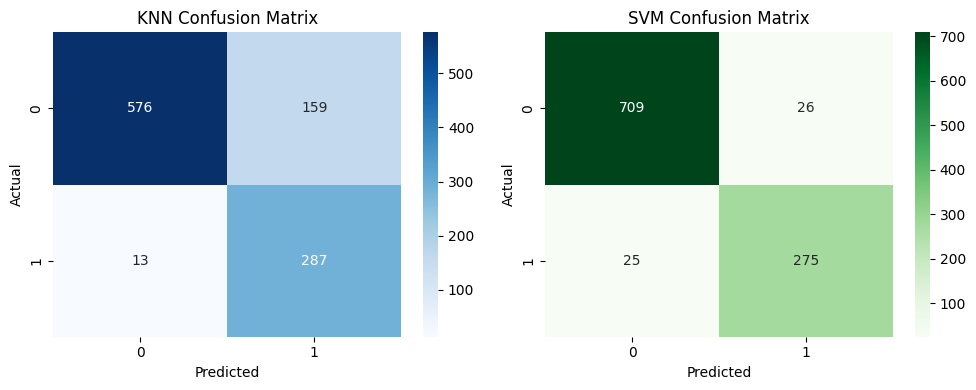

In [9]:
knn_cm = confusion_matrix(y_test, knn_predictions)
svm_cm = confusion_matrix(y_test, svm_predictions)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(knn_cm, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("KNN Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(svm_cm, annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("SVM Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()